El siguiente cuadernillo permite aplicar la metodología desarrollada en el proyecto de investigación a un comentario específico, con el propósito de identificar su tópico y emoción asociados. Esta funcionalidad facilita la validación de los resultados, amplía el alcance predictivo del modelo y abre nuevas posibilidades para futuras investigaciones en esta línea de trabajo.

# Importaciones

In [1]:
import html
import json
import os
import pickle
import re
import unicodedata
from pathlib import Path
import emoji
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

BASE = Path(r"C:\Users\samue\OneDrive - Universidad Externado de Colombia\Proyectos\Diagnóstico Psicológico\Repositorio")
RUTA_EMB = BASE / "Sent_2" / "embeddings.npy"                    # embeddings REFINADOS (n x 48)
RUTA_RMHD = BASE / "Sent_2" / "RMHD_con_emociones_new.parquet"
GRAFOS_DIR = BASE / "Sent_2"
ART = BASE / "Codigo" / "artefactos_clasificacion"

MODELO_EMB = "BAAI/bge-small-en-v1.5"
DEVICE = "cpu"              
SUBREDDITS = ["Anxiety", "SuicideWatch", "depression"]

# Centroides
Inicialmente, se obtienen los centroides de cada una de las comunidades, permitiendo identificar el tópico más cercano a los nuevos comentarios.

In [2]:
def l2(x, eps=1e-12):
    return x / np.maximum(np.linalg.norm(x, axis=-1, keepdims=True), eps)


def extraer_de_grafo(G):
    """(orig_index, community, topics) desde un igraph.Graph ya cargado."""
    attrs = G.vertex_attributes()
    if "orig_index" not in attrs or "community" not in attrs:
        raise KeyError(f"El grafo no tiene 'orig_index' y/o 'community'. Atributos: {attrs}")
    orig = np.asarray(G.vs["orig_index"], dtype=np.int64)
    comm = np.asarray(G.vs["community"], dtype=np.int64)
    topics = {}
    if "topic" in attrs:
        for c, t in zip(comm, G.vs["topic"]):
            topics.setdefault(int(c), [w.strip() for w in str(t).split(",") if w.strip()])
    return orig, comm, topics


def procesar_subreddit(emb, sub_idx, orig_idx, comm, topics=None,
                       n_validacion=20000, seed=42):
    """
    emb      : matriz completa de embeddings REFINADOS (n_total x dim)
    sub_idx  : posiciones (0..n_total-1) de TODOS los comentarios del subreddit
    orig_idx : posición en el dataset de cada nodo del grafo; comm: su comunidad
    Devuelve (C, ids, mu, info_comunidades, concordancia).
    """
    topics = topics or {}
    dim = emb.shape[1]
    sub_idx = np.asarray(sub_idx)
    X = np.array(emb[sub_idx], dtype=np.float32)
    mu = X.mean(axis=0)
    X -= mu
    X = l2(X)

    pos = np.searchsorted(sub_idx, orig_idx)
    ok = (pos < len(sub_idx)) & (sub_idx[np.minimum(pos, len(sub_idx) - 1)] == orig_idx)
    if not ok.all():
        raise ValueError(f"{(~ok).sum()} nodos del grafo no pertenecen a este subreddit "
                         "(¿grafo y parquet no corresponden?).")

    ids = np.array(sorted(set(comm.tolist())), dtype=np.int64)
    C = np.zeros((len(ids), dim), dtype=np.float32)
    info = []
    for k, c in enumerate(ids):
        miembros = pos[comm == c]
        C[k] = l2(X[miembros].mean(axis=0))
        palabras = topics.get(int(c), [])
        info.append({"comm": int(c), "n": int(len(miembros)),
                     "topic_words": palabras, "topic_full": ", ".join(palabras),
                     "cohesion_media": round(float((X[miembros[:5000]] @ C[k]).mean()), 4)})

    rng = np.random.default_rng(seed)
    m = min(n_validacion, len(pos))
    s = rng.choice(len(pos), size=m, replace=False)
    pred = ids[np.argmax(X[pos[s]] @ C.T, axis=1)]
    concord = float((pred == comm[s]).mean())
    return C, ids, mu.astype(np.float32), info, concord


def guardar_artefactos(resultados, modelo, dim, out_dir, proyeccion=None):
    """resultados: {sub: dict(C, ids, mu, info, concordancia, n_subreddit, n_en_comunidades)}"""
    os.makedirs(out_dir, exist_ok=True)
    npz, meta = {}, {"modelo_embeddings": modelo, "dim": int(dim),
                     "centrado_por_subreddit": True, "proyeccion": proyeccion, "subreddits": {}}
    for sub, r in resultados.items():
        npz[f"{sub}__C"], npz[f"{sub}__ids"], npz[f"{sub}__mu"] = r["C"], r["ids"], r["mu"]
        meta["subreddits"][sub] = {"n_subreddit": r["n_subreddit"],
                                   "n_en_comunidades": r["n_en_comunidades"],
                                   "concordancia_muestra": round(r["concordancia"], 4),
                                   "comunidades": r["info"]}
    np.savez_compressed(os.path.join(out_dir, "centroides.npz"), **npz)
    with open(os.path.join(out_dir, "comunidades.json"), "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

## Muestra de referencia para la proyección
Los centroides viven en el espacio refinado (UMAP, 42 dimensiones), pero un comentario nuevo sale del modelo BGE en 384 dimensiones. Como no se conservó el UMAP, se proyecta por vecinos usando una muestra del corpus ya re-embebida. Esta celda se ejecuta una sola vez (si los archivos existen, no se repite).

In [3]:
def embeber(textos, nombre_modelo=MODELO_EMB, device=DEVICE, batch_size=128):
    from sentence_transformers import SentenceTransformer
    m = SentenceTransformer(nombre_modelo, device=device)
    m.max_seq_length = 512
    return m.encode(list(textos), batch_size=batch_size, convert_to_numpy=True,
                    normalize_embeddings=True, show_progress_bar=True)


N_REF = 100_000
ART.mkdir(parents=True, exist_ok=True)

rmhd_df = pd.read_parquet(RUTA_RMHD, columns=["subreddit", "text_clean"])
emb = np.load(RUTA_EMB, mmap_mode="r")
assert len(rmhd_df) == len(emb), f"Desalineación: {len(rmhd_df)} vs {len(emb)}"

if not (ART / "ref_embeddings.npy").exists():
    rng = np.random.default_rng(42)
    validas = np.flatnonzero(rmhd_df["text_clean"].fillna("").str.len().to_numpy() > 0)
    ref_idx = np.sort(rng.choice(validas, size=min(N_REF, len(validas)), replace=False))
    E_ref = embeber(rmhd_df["text_clean"].iloc[ref_idx])
    np.save(ART / "ref_embeddings.npy", E_ref.astype(np.float32))
    np.save(ART / "ref_refinados.npy", np.asarray(emb[ref_idx], dtype=np.float32))
    np.save(ART / "ref_indices.npy", ref_idx)
else:
    print("La muestra de referencia ya existe; no se recalcula.")

PROY = {"tipo": "knn", "k": 5,
        "embeddings_originales": "ref_embeddings.npy", "embeddings_refinados": "ref_refinados.npy"}

La muestra de referencia ya existe; no se recalcula.


In [4]:
res = {}
for sub in SUBREDDITS:
    with open(GRAFOS_DIR / f"Grafo_{sub}_best.pkl", "rb") as f:
        G = pickle.load(f)
    orig, comm, topics = extraer_de_grafo(G)
    sub_idx = np.flatnonzero(rmhd_df["subreddit"].to_numpy() == sub)
    C, ids, mu, info, conc = procesar_subreddit(emb, sub_idx, orig, comm, topics)
    print(f"[r/{sub}] {len(ids)} comunidades | concordancia {conc:.3f}")
    res[sub] = dict(C=C, ids=ids, mu=mu, info=info, concordancia=conc,
                    n_subreddit=int(len(sub_idx)), n_en_comunidades=int(len(orig)))
guardar_artefactos(res, MODELO_EMB, emb.shape[1], ART, proyeccion=PROY)
print("[OK] artefactos guardados en", ART)
centroides = np.load(ART / "centroides.npz")
print(centroides.files)

[r/Anxiety] 10 comunidades | concordancia 0.791
[r/SuicideWatch] 10 comunidades | concordancia 0.824
[r/depression] 12 comunidades | concordancia 0.776
[OK] artefactos guardados en C:\Users\samue\OneDrive - Universidad Externado de Colombia\Proyectos\Diagnóstico Psicológico\Repositorio\Codigo\artefactos_clasificacion
['Anxiety__C', 'Anxiety__ids', 'Anxiety__mu', 'SuicideWatch__C', 'SuicideWatch__ids', 'SuicideWatch__mu', 'depression__C', 'depression__ids', 'depression__mu']


# Clasificación
Una vez definidos los centroides, se realiza el flujo de preprocesamiento análogo al que se realizó con el dataset original y la predicción de los nuevos comentarios.

In [5]:
BAD_TEXTS = {"", ".", "..", "...", "none", "null", "nan", "title",
             "pls", "please", "[deleted]", "[removed]"}

# Palabras que el pipeline original eliminó tras lematizar
ELIMINAR_TRAS_LEMA = {"m", "hello", "hi", "url", "well", "hey", "okay", "bye",
                      "sure", "pm", "ok", "not", "thank"}

USER_RE = re.compile(r"\bu/\w+")
SUBREDDIT_RE = re.compile(r"\br/\w+")
REMOVED_RE = re.compile(r"\[deleted\]|\[removed\]", flags=re.IGNORECASE)
URL_TOKEN_RE = re.compile(r"\bURL\b")
EMOJI_RE = re.compile(r":[a-z0-9_\-+&.']+:", flags=re.IGNORECASE)


def clean_text(t):
    """Limpieza general (celda 23). Devuelve None si el texto es basura."""
    if t is None:
        return None
    t = html.unescape(str(t))
    t = emoji.demojize(t)
    t = re.sub(r"[‘’ʼ´`]", "'", t)
    t = re.sub(r"\\'", "'", t)
    t = re.sub(r"\[.*?\]\(https?://.*?(?:\s|\))", " ", t)
    t = re.sub(r"https?://\S+|www\.\S+", " URL ", t)
    t = re.sub(r"\s+", " ", t).strip()
    if t.lower() in BAD_TEXTS or re.fullmatch(r"[.\-_]+", t):
        return None
    return t


def normalize_text(text):
    """Normalización previa a la lematización (celda 42)."""
    if not isinstance(text, str):
        return ""
    text = USER_RE.sub(" ", text)
    text = SUBREDDIT_RE.sub(" ", text)
    text = REMOVED_RE.sub(" ", text)
    text = URL_TOKEN_RE.sub(" ", text)
    text = EMOJI_RE.sub(" ", text)
    text = unicodedata.normalize("NFKC", text)
    return text.lower()


def cargar_spacy():
    import spacy
    return spacy.load("en_core_web_sm", disable=["parser", "ner"])


def lematizar(texto_normalizado, nlp):
    """Lemas alfabéticos sin stopwords, unidos por espacio (celda 42)."""
    doc = nlp(texto_normalizado)
    return " ".join(t.lemma_ for t in doc if t.is_alpha and not t.is_stop)


def preparar(texto, nlp):
    """
    Devuelve (texto_limpio, texto_lematizado).
    texto_limpio es None si el comentario es basura; texto_lematizado es ""
    si tras lematizar no queda contenido (o queda una palabra de la lista de descarte).
    """
    limpio = clean_text(texto)
    if limpio is None:
        return None, ""
    lema = lematizar(normalize_text(limpio), nlp)
    if lema in ELIMINAR_TRAS_LEMA:
        lema = ""
    return limpio, lema

Teniendo la salida ya limpia para el comentario, se procede a realizar la predicción tanto de emoción como de tópico.

In [6]:
# CORREGIDO: se renombra a SUBREDDIT_MAP (antes pisaba la lista SUBREDDITS de la celda de centroides).
SUBREDDIT_MAP = {"anxiety": "Anxiety", "suicidewatch": "SuicideWatch", "depression": "depression"}

# Agrupación emocional de acuerdo con el modelo emocional de Ekman  (CORREGIDO: «Eckman» -> «Ekman»)
EKMAN = {
    "anger":    ["anger", "annoyance", "disapproval"],
    "disgust":  ["disgust"],
    "fear":     ["fear", "nervousness"],
    "happiness":      ["joy", "amusement", "approval", "excitement", "gratitude", "love",
                 "optimism", "relief", "pride", "admiration", "desire", "caring"],
    "sadness":  ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "surprise": ["surprise", "realization", "confusion", "curiosity"],
    "neutral":  ["neutral"],
}
EMO_ES = {"anger": "Ira", "disgust": "Disgusto", "fear": "Miedo", "happiness": "Alegría",
          "sadness": "Tristeza", "surprise": "Sorpresa", "neutral": "Neutral"}
MAX_CHARS = 2000          # notebook 2, celda 13
MIN_PALABRAS = 5          # notebook 3, aplicar_regla_neutral_cortos
EMO_MODEL = "SamLowe/roberta-base-go_emotions"


def normalizar_subreddit(s):
    k = (s or "").strip().lower().replace("r/", "")
    if k not in SUBREDDIT_MAP:
        raise ValueError(f"Subreddit no válido: {s!r}. Opciones: {sorted(SUBREDDIT_MAP.values())}")
    return SUBREDDIT_MAP[k]


# CORREGIDO: se restituye la proyección al espacio refinado. Sin este paso el embedding nuevo (384-d) se compara
# con centroides de 42-d y el clasificador lanza «Dimensión del embedding ≠ centroides».
class ProyectorVecinos:
    """
    Aproxima el UMAP: proyecta un embedding como el promedio ponderado de las coordenadas refinadas de sus k vecinos
    más cercanos (coseno) en la muestra de referencia. NO equivale a UMAP.transform; debe declararse como aproximación.
    """
    def __init__(self, E_ref, R_ref, k=5):
        self.E = np.asarray(E_ref, dtype=np.float32)
        self.R = np.asarray(R_ref, dtype=np.float32)
        self.k = k
        self.norms = np.maximum(np.linalg.norm(self.E, axis=1), 1e-12)

    def __call__(self, e):
        e = np.asarray(e, dtype=np.float32)
        e = e / max(np.linalg.norm(e), 1e-12)
        s = (self.E @ e) / self.norms
        top = np.argpartition(-s, self.k)[: self.k]
        w = 1.0 / (1e-6 + (1.0 - np.clip(s[top], -1, 1)))
        return (self.R[top] * w[:, None]).sum(0) / w.sum()


def cargar_proyector(meta_proy, artefactos_dir):
    if not meta_proy:
        return lambda e: e
    if meta_proy["tipo"] == "knn":
        d = Path(artefactos_dir)
        return ProyectorVecinos(np.load(d / meta_proy["embeddings_originales"]),
                                np.load(d / meta_proy["embeddings_refinados"]), k=meta_proy.get("k", 5))
    raise ValueError(f"Tipo de proyección desconocido: {meta_proy['tipo']}")


class ClasificadorComentarios:
    # CORREGIDO: el cálculo de la muestra de referencia estaba pegado dentro de __init__ (se re-embebían 100 000
    # comentarios en CADA instanciación y usaba variables inexistentes en ese ámbito). Ahora vive en su propia celda.
    def __init__(self, artefactos_dir, device=DEVICE, embedder=None, emotion_clf=None, nlp=None, proyector=None):
        """embedder / emotion_clf / nlp / proyector se pueden inyectar (pruebas); si no, se cargan."""
        artefactos_dir = Path(artefactos_dir)
        with open(artefactos_dir / "comunidades.json", encoding="utf-8") as f:
            self.meta = json.load(f)
        z = np.load(artefactos_dir / "centroides.npz")
        self.C = {s: z[f"{s}__C"] for s in SUBREDDIT_MAP.values()}
        self.ids = {s: z[f"{s}__ids"] for s in SUBREDDIT_MAP.values()}
        self.mu = {s: z[f"{s}__mu"] for s in SUBREDDIT_MAP.values()}
        self.info = {s: {c["comm"]: c for c in self.meta["subreddits"][s]["comunidades"]}
                     for s in SUBREDDIT_MAP.values()}
        self.nlp = nlp or cargar_spacy()
        self.proyector = proyector or cargar_proyector(self.meta.get("proyeccion"), artefactos_dir)

        if embedder is None:
            from sentence_transformers import SentenceTransformer
            embedder = SentenceTransformer(self.meta["modelo_embeddings"], device=device)
            embedder.max_seq_length = 512
        self.embedder = embedder

        if emotion_clf is None:
            from transformers import pipeline
            emotion_clf = pipeline("text-classification", model=EMO_MODEL, top_k=None,
                                   truncation=True, max_length=512,
                                   device=-1 if device == "cpu" else 0)
        self.emotion_clf = emotion_clf

    # ---------------- emoción ----------------
    def _emocion(self, texto_limpio):
        t = " ".join(texto_limpio.split())[:MAX_CHARS]
        salida = self.emotion_clf([t])[0]
        p = {d["label"]: float(d["score"]) for d in salida}
        scores = {emo: max(p[l] for l in labels) for emo, labels in EKMAN.items()}
        emo = max(scores, key=scores.get)                      # argmax, igual que idxmax
        corto = len(texto_limpio.split()) < MIN_PALABRAS       # regla original
        if corto:
            emo = "neutral"
        ranking = sorted(scores.items(), key=lambda x: x[1], reverse=True)
        return {
            "predominante": emo, "predominante_es": EMO_ES[emo],
            "score_predominante": round(scores[emo], 4),
            "scores": {k: round(v, 4) for k, v in ranking},
            "regla_neutral_texto_corto": corto,
            "etiquetas_goemotions_top3": sorted(p.items(), key=lambda x: -x[1])[:3],
        }

    # ---------------- comunidad ----------------
    def _comunidad(self, texto_lematizado, sub, top_n=3):
        if not texto_lematizado:
            return {"asignada": None,
                    "aviso": "El texto no tiene contenido léxico tras la limpieza; no se puede asignar comunidad."}
        e = self.embedder.encode([texto_lematizado], convert_to_numpy=True,
                                 normalize_embeddings=True)[0].astype(np.float32)
        e = np.asarray(self.proyector(e), dtype=np.float32)    # CORREGIDO: 384-d -> espacio refinado (42-d)
        if e.shape[0] != self.C[sub].shape[1]:
            raise RuntimeError(f"Dimensión del embedding ({e.shape[0]}) ≠ centroides ({self.C[sub].shape[1]})")
        e = e - self.mu[sub]                                   # mismo centrado que el grafo
        e = e / max(np.linalg.norm(e), 1e-12)
        sims = self.C[sub] @ e
        orden = np.argsort(-sims)

        def item(k):
            cid = int(self.ids[sub][k]); inf = self.info[sub].get(cid, {})
            return {"comm": cid, "similitud": round(float(sims[k]), 4),
                    "topic_full": inf.get("topic_full", ""), "n_comentarios": inf.get("n")}
        ranking = [item(k) for k in orden[:top_n]]
        return {"asignada": ranking[0], "ranking": ranking}

    # ---------------- flujo completo ----------------
    def clasificar(self, comentario, subreddit):
        if comentario is None or not str(comentario).strip():
            raise ValueError("El comentario está vacío.")
        sub = normalizar_subreddit(subreddit)
        limpio, lema = preparar(comentario, self.nlp)
        if limpio is None:
            raise ValueError("El comentario no contiene texto utilizable.")
        return {"subreddit": sub, "comentario": comentario,
                "texto_limpio": limpio, "texto_lematizado": lema,
                "comunidad": self._comunidad(lema, sub),
                "emocion": self._emocion(limpio),
                "nota": "La comunidad se asigna por similitud coseno a centroides: aproximación "
                        "semántica, no una nueva ejecución de Leiden."}

In [7]:
comentario = "I'm honestly terrified about these new variants. Every time I hear about Pfizer or Moderna updates, I start worrying that we're going back to those days when nobody knew what was going to happen."
subreddit = "Anxiety"
clf = ClasificadorComentarios(ART)
print(json.dumps(clf.clasificar(comentario, subreddit), ensure_ascii=False, indent=2))

Device set to use cpu


{
  "subreddit": "Anxiety",
  "comentario": "I'm honestly terrified about these new variants. Every time I hear about Pfizer or Moderna updates, I start worrying that we're going back to those days when nobody knew what was going to happen.",
  "texto_limpio": "I'm honestly terrified about these new variants. Every time I hear about Pfizer or Moderna updates, I start worrying that we're going back to those days when nobody knew what was going to happen.",
  "texto_lematizado": "honestly terrified new variant time hear pfizer moderna update start worry go day know go happen",
  "comunidad": {
    "asignada": {
      "comm": 2,
      "similitud": 0.7782,
      "topic_full": "ecg, gabapentin, mirtazapine, fluoxetine, cymbalta",
      "n_comentarios": 104105
    },
    "ranking": [
      {
        "comm": 2,
        "similitud": 0.7782,
        "topic_full": "ecg, gabapentin, mirtazapine, fluoxetine, cymbalta",
        "n_comentarios": 104105
      },
      {
        "comm": 0,
        "si

# Evaluación del Benchmark

Una vez realizado el flujo funcional para la clasificación, se evalúan los resultados en un dataset sintético con 4 comentarios para cada comunidad, cada uno con una emoción diferente

In [8]:
bench = pd.read_csv(
    "Comentarios sinteticos.csv",
    usecols=["text", "subreddit", "community", "emotion"]
)

comunidades_pred = []
emociones_pred = []

for _, row in bench.iterrows():
    resultado = clf.clasificar(row["text"], row["subreddit"])

    comunidades_pred.append(resultado["comunidad"]["asignada"]["comm"])
    emociones_pred.append(resultado["emocion"]["predominante"])

bench["comunidad_pred"] = comunidades_pred
bench["emocion_pred"] = emociones_pred

In [9]:
bench

,text,subreddit,community,emotion,comunidad_pred,emocion_pred
0,I keep checking every update about new variant...,Anxiety,0,fear,0,fear
1,"My family argues about Pfizer and Moderna, and...",Anxiety,0,anger,9,anger
2,I was surprised to learn how much the guidance...,Anxiety,0,surprise,7,surprise
3,I read the public health updates this morning ...,Anxiety,0,neutral,7,neutral
4,"My GPA has dropped this semester, and I am ter...",Anxiety,1,fear,1,fear
...,...,...,...,...,...,...
123,I am looking into practical housing and financ...,depression,10,neutral,0,neutral
124,Even brushing my teeth feels impossible some m...,depression,11,sadness,11,sadness
125,"I get anxious when I think about showering, cl...",depression,11,fear,11,fear
126,I felt unexpectedly proud after taking a showe...,depression,11,happiness,11,happiness


In [10]:
# Tópicos
bench["comunidad_real_global"] = (
    bench["subreddit"] + "_" + bench["community"].astype(str)
)

bench["comunidad_pred_global"] = (
    bench["subreddit"] + "_" + bench["comunidad_pred"].astype(str)
)

y_true_com = bench["comunidad_real_global"]
y_pred_com = bench["comunidad_pred_global"]

# Emociones

y_true_emo = bench["emotion"]
y_pred_emo = bench["emocion_pred"]

# Métricas

def evaluar_modelo(y_true, y_pred, nombre):

    metricas = {
        "Tarea": nombre,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision Macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall Macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 Macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Precision Weighted": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall Weighted": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1 Weighted": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

    return metricas

resultados = pd.DataFrame([
    evaluar_modelo(y_true_com, y_pred_com, "Comunidades"),
    evaluar_modelo(y_true_emo, y_pred_emo, "Emociones")
])

print("\nMÉTRICAS GENERALES")
display(resultados.round(4))


# Métricas por cada clase

print("\nREPORTE DE COMUNIDADES")
reporte_com = classification_report(
    y_true_com,
    y_pred_com,
    output_dict=True,
    zero_division=0
)

reporte_com = pd.DataFrame(reporte_com).T
display(reporte_com.round(4))


print("\nREPORTE DE EMOCIONES")
reporte_emo = classification_report(
    y_true_emo,
    y_pred_emo,
    output_dict=True,
    zero_division=0
)

reporte_emo = pd.DataFrame(reporte_emo).T
display(reporte_emo.round(4))


MÉTRICAS GENERALES


,Tarea,Accuracy,Balanced Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Weighted,Recall Weighted,F1 Weighted
0,Comunidades,0.3984,0.3984,0.4360,0.3984,0.3705,0.4360,0.3984,0.3705
1,Emociones,0.8906,0.8492,0.8509,0.8492,0.8487,0.8981,0.8906,0.8927



REPORTE DE COMUNIDADES


,precision,recall,f1-score,support
Anxiety_0,1.0000,0.2500,0.4000,4.0000
Anxiety_1,1.0000,0.5000,0.6667,4.0000
Anxiety_2,0.5000,0.2500,0.3333,4.0000
Anxiety_3,1.0000,0.5000,0.6667,4.0000
Anxiety_4,1.0000,0.2500,0.4000,4.0000
Anxiety_5,0.3750,0.7500,0.5000,4.0000
Anxiety_6,0.0000,0.0000,0.0000,4.0000
Anxiety_7,0.2308,0.7500,0.3529,4.0000
Anxiety_8,0.0000,0.0000,0.0000,4.0000
Anxiety_9,0.2000,0.5000,0.2857,4.0000



REPORTE DE EMOCIONES


,precision,recall,f1-score,support
anger,1.0000,0.9333,0.9655,15.0000
disgust,0.5000,0.5000,0.5000,2.0000
fear,0.9600,0.9600,0.9600,25.0000
happiness,0.7083,0.8500,0.7727,20.0000
neutral,0.9310,0.8438,0.8852,32.0000
sadness,0.8571,0.8571,0.8571,21.0000
surprise,1.0000,1.0000,1.0000,13.0000
accuracy,0.8906,0.8906,0.8906,0.8906
macro avg,0.8509,0.8492,0.8487,128.0000
weighted avg,0.8981,0.8906,0.8927,128.0000


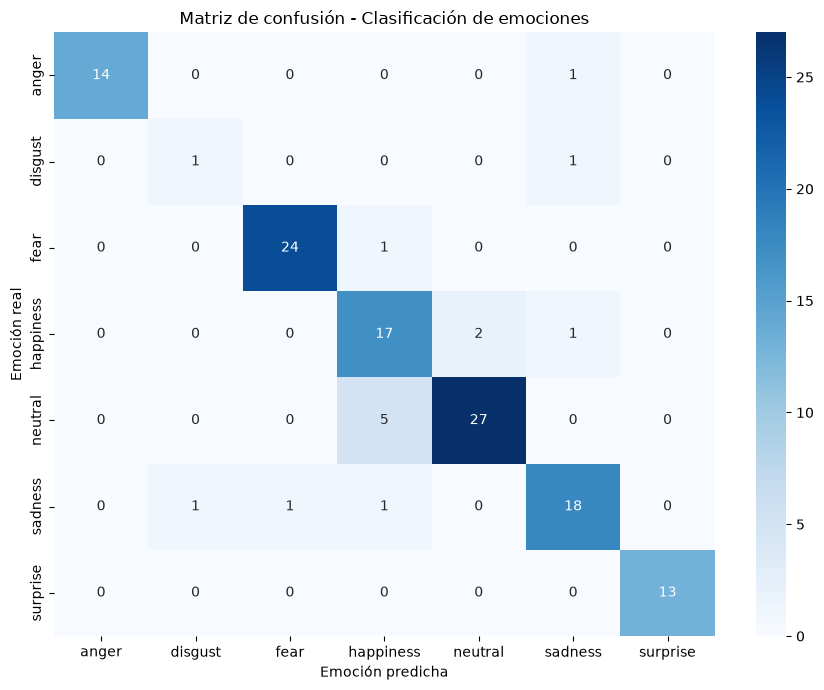

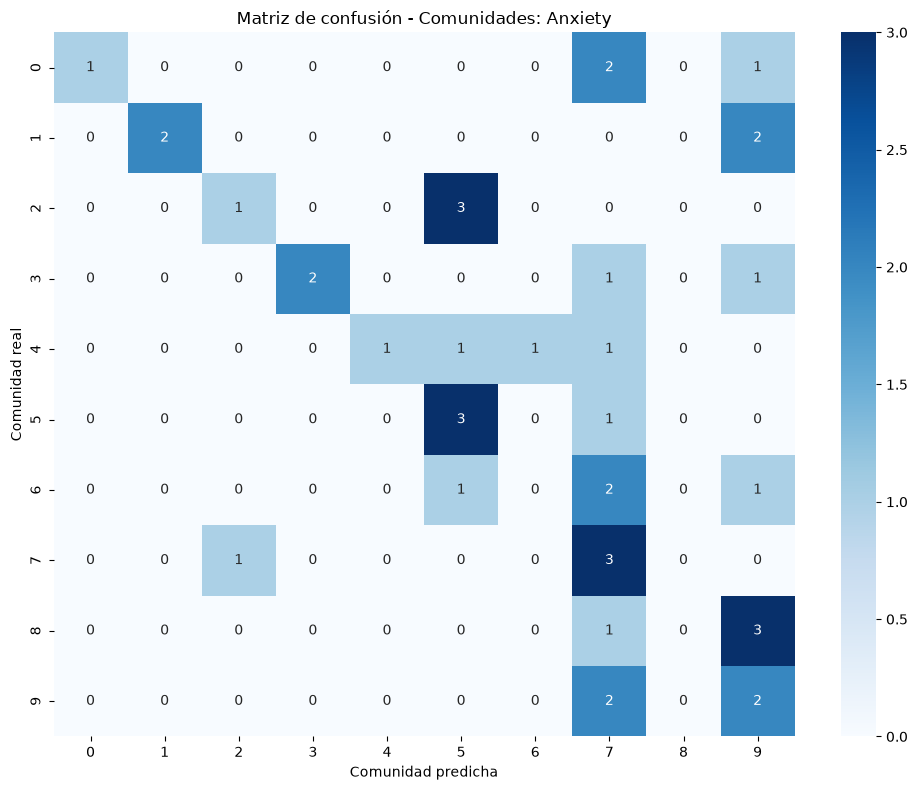

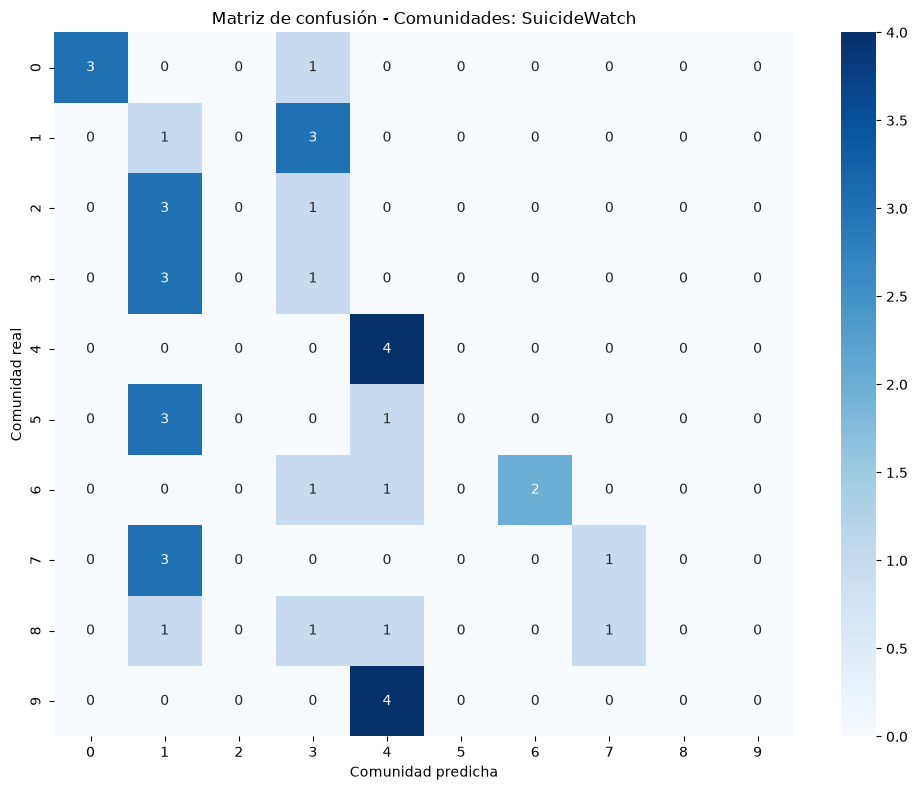

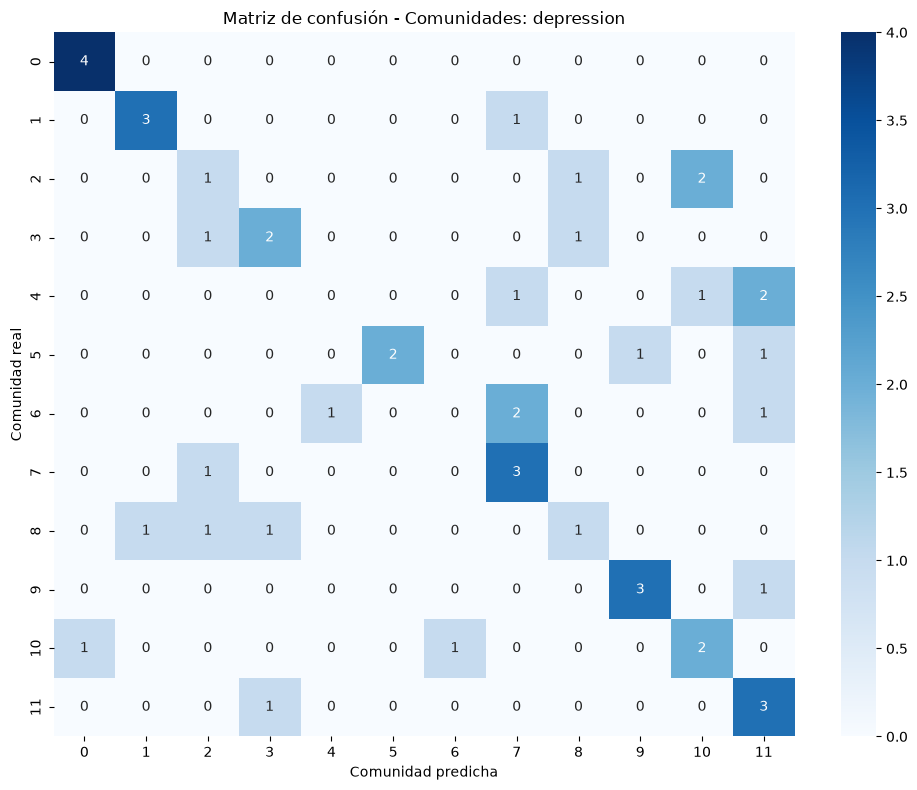

In [11]:
# Matriz de confusión de emociones
cm_emo = confusion_matrix(
    y_true_emo,
    y_pred_emo,
    labels=sorted(y_true_emo.unique())
)

labels_emo = sorted(y_true_emo.unique())

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_emo,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels_emo,
    yticklabels=labels_emo
)

plt.title("Matriz de confusión - Clasificación de emociones")
plt.xlabel("Emoción predicha")
plt.ylabel("Emoción real")
plt.tight_layout()
plt.show()


# Matrices de confusión de comunidades por subreddit
for subreddit in sorted(bench["subreddit"].unique()):

    subset = bench[bench["subreddit"] == subreddit]

    labels = sorted(
        set(subset["community"]) |
        set(subset["comunidad_pred"])
    )

    cm = confusion_matrix(
        subset["community"],
        subset["comunidad_pred"],
        labels=labels
    )

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(f"Matriz de confusión - Comunidades: {subreddit}")
    plt.xlabel("Comunidad predicha")
    plt.ylabel("Comunidad real")
    plt.tight_layout()
    plt.show()
